# Architecture Transformer

## Avant 2017 : RNN, LSTM, GRU

### 1. RNN

#### Qu'est-ce qu'un RNN ?
Un **réseau de neurones récurrent** (*Recurrent Neural Network*) traite des données organisées en séquences : séries temporelles, textes, signaux, etc.

Il lit les éléments **dans l'ordre** et met à jour un **état caché**, qui joue le rôle de mémoire des informations précédentes.

#### Architecture générale
À chaque instant $t$, une cellule RNN reçoit :
* l'entrée actuelle $x_t$ ;
* l'état caché précédent $h_{t-1}$.

Elle calcule un nouvel état caché :
$$h_t = \tanh(W_{ih} x_t + W_{hh} h_{t-1} + b)$$

Les poids $W_{ih}$, $W_{hh}$ et le biais $b$ sont appris pendant l'entraînement. Les mêmes paramètres sont utilisés à tous les instants.

#### Architecture de notre exemple
Le modèle utilise 10 valeurs d'une sinusoïde pour prédire la suivante.

| Élément | Rôle |
| :--- | :--- |
| `input_size=1` | Une variable observée à chaque instant |
| Séquence de longueur 10 | Dix valeurs lues successivement |
| `hidden_size=16` | Une mémoire composée de 16 nombres |
| `nn.Linear(16, 1)` | Transformation de la dernière mémoire en une prédiction |

Avec `batch_first=True`, les dimensions sont :
$$(B, 10, 1) \xrightarrow{\text{RNN}} (B, 10, 16) \xrightarrow{\text{dernier état}} (B, 16) \xrightarrow{\text{Linear}} (B, 1)$$
$B$ représente le nombre de séquences traitées ensemble.

#### Fonctionnement
1. **Initialisation :** l'état caché commence à zéro pour chaque séquence.
2. **Lecture :** le RNN lit les valeurs une par une.
3. **Mémoire :** à chaque instant, il combine la nouvelle entrée avec l'état précédent.
4. **Prédiction :** dans notre modèle, la couche linéaire utilise uniquement le dernier état caché.
5. **Apprentissage :** la MSE mesure l'erreur, la rétropropagation à travers le temps calcule les gradients et Adam ajuste les paramètres.

#### Limite principale
Un RNN classique peut avoir du mal à apprendre des dépendances sur de longues séquences, notamment à cause des gradients qui disparaissent ou explosent. Les LSTM et les GRU sont des variantes conçues pour mieux gérer la mémoire à long terme.

> **À retenir :** un RNN réutilise les mêmes paramètres pour lire une séquence et actualiser sa mémoire à chaque instant.

### Génération d'un exemple de dataset

In [1]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# ---------------------------------------------------------
# 1. Créer les données
# ---------------------------------------------------------
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

longueur_sequence = 10

# Chaque entrée contient 10 valeurs.
# La cible est la valeur immédiatement suivante.
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Un RNN attend (nombre de séquences, longueur, nombre de variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : début pour apprendre, fin pour tester.
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

Text(0, 0.5, 'y')

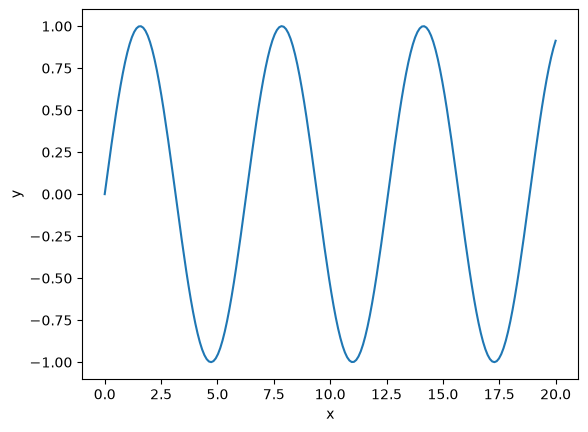

In [2]:
import matplotlib.pyplot as plt
plt.plot(periode, serie)
plt.xlabel("x")
plt.ylabel("y")

In [3]:
# ---------------------------------------------------------
# 2. Définir le modèle
# ---------------------------------------------------------
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(
            input_size=1,       # Une valeur à chaque instant
            hidden_size=16,     # Une mémoire composée de 16 nombres
            batch_first=True
        )
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Si aucun état initial n'est fourni, PyTorch utilise des zéros.
        etats, _ = self.rnn(x)          # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Transformer la mémoire finale en une valeur prédite.
        return self.sortie(dernier_etat)

modele = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

### Explication du code : préparer les données et définir un RNN

Le modèle doit apprendre à prédire la prochaine valeur d'une sinusoïde à partir de ses 10 valeurs précédentes.

1. **Préparation des données :** Création de 200 points avec `torch.linspace(0, 20, 200)` puis application de `torch.sin`. Construction de 190 fenêtres glissantes de taille 10 (`X` de forme `(190, 10, 1)` et `y` de forme `(190, 1)`). Découpage chronologique en 150 séquences d'entraînement et 40 de test.
2. **Architecture `SimpleRNN` :** Une couche récurrente `nn.RNN(input_size=1, hidden_size=16, batch_first=True)` suivie d'une couche linéaire `nn.Linear(16, 1)` appliquée au dernier état caché `etats[:, -1, :]`.

### Entraînement du RNN

In [4]:
# ---------------------------------------------------------
# 3. Entraîner le modèle
# ---------------------------------------------------------
modele.train()
for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()  # Effacer les anciens gradients
    perte.backward()        # Calculer les nouveaux gradients
    optimiseur.step()       # Mettre à jour les paramètres

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

# ---------------------------------------------------------
# 4. Tester le modèle
# ---------------------------------------------------------
modele.eval()
with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025

Erreur de test : 0.000028
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


In [5]:
predictions.shape

torch.Size([40, 1])

### Visualiser les prédictions

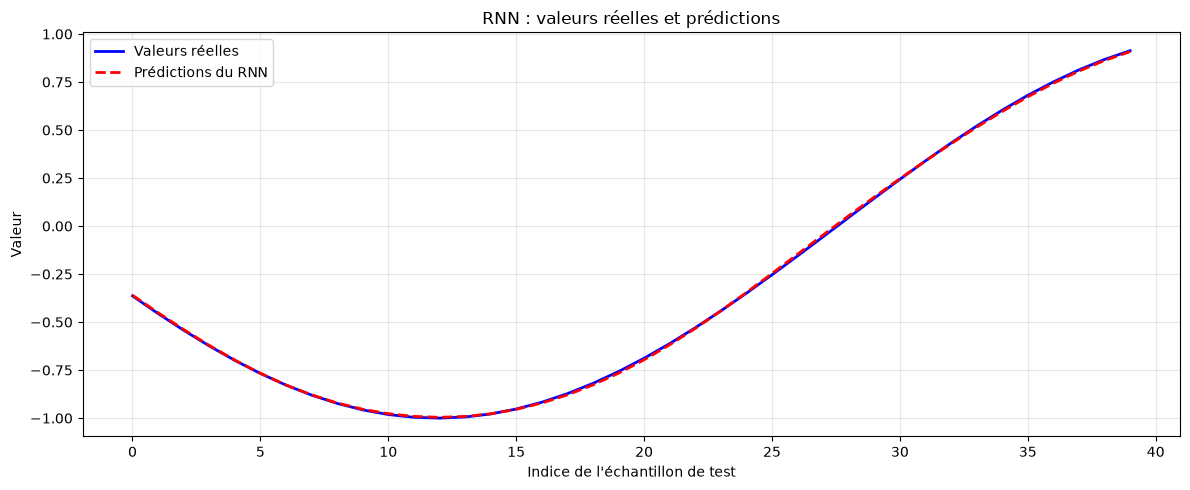

In [6]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))
plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)
plt.plot(
    valeurs_predites,
    label="Prédictions du RNN",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2. LSTM

#### Définition
Un **LSTM** (*Long Short-Term Memory*) est une variante du RNN conçue pour mieux apprendre les dépendances à long terme dans une séquence.

Il transmet deux états d'un instant au suivant :
* **L'état caché $h_t$ :** la représentation produite à l'instant courant.
* **L'état de cellule $c_t$ :** une mémoire interne permettant de conserver des informations dans le temps.

#### Architecture d'une cellule LSTM
À chaque instant $t$, la cellule reçoit $x_t$, $h_{t-1}$ et $c_{t-1}$. Elle utilise trois portes (valeurs entre 0 et 1) :
* **Porte d'oubli $f_t$ :** Déterminer quelles informations de la mémoire précédente conserver.
* **Porte d'entrée $i_t$ :** Contrôler l'ajout de nouvelles informations.
* **Porte de sortie $o_t$ :** Contrôler les informations exposées dans l'état caché.

Les mises à jour sont :
$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$$
$$h_t = o_t \odot \tanh(c_t)$$

> **À retenir :** un LSTM apprend quelles informations conserver, ajouter et exposer grâce à une mémoire interne contrôlée par des portes.

In [7]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# ---------------------------------------------------------
# 1. Créer les données
# ---------------------------------------------------------
serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme attendue : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

# ---------------------------------------------------------
# 2. Définir le modèle LSTM
# ---------------------------------------------------------
class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1,       # Une variable à chaque instant
            hidden_size=16,     # 16 unités cachées
            num_layers=1,       # Une seule couche LSTM
            batch_first=True
        )
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Sans états initiaux fournis, h0 et c0 sont mis à zéro.
        etats, (h_final, c_final) = self.lstm(x)  # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]            # (nombre de séquences, 16)

        # Une prédiction par séquence
        return self.sortie(dernier_etat)

modele = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

# ---------------------------------------------------------
# 3. Entraîner le modèle
# ---------------------------------------------------------
modele.train()
for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

# ---------------------------------------------------------
# 4. Tester le modèle
# ---------------------------------------------------------
modele.eval()
with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248
Epoch 150 | Erreur : 0.000043
Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003

Erreur de test : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


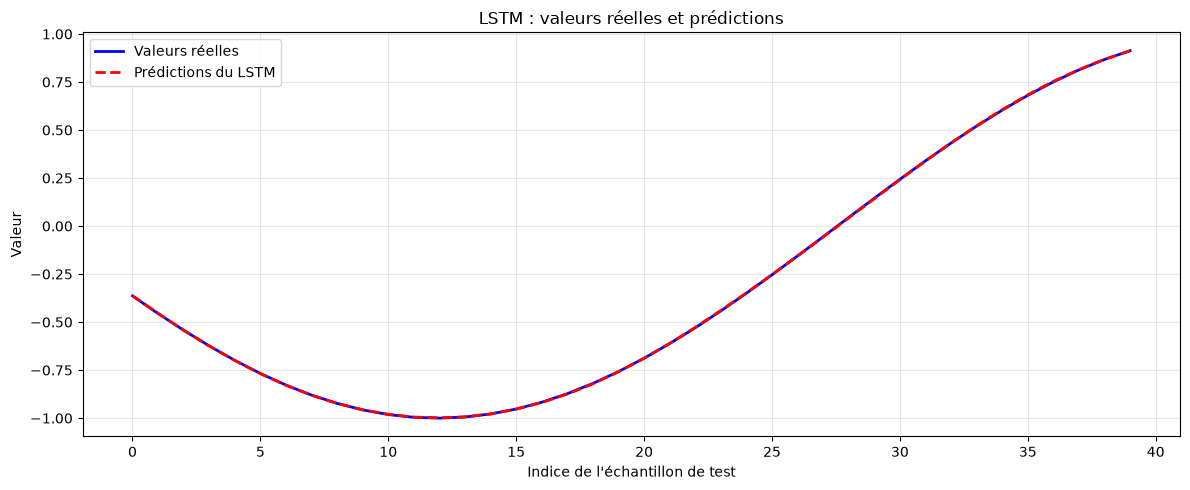

In [8]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))
plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)
plt.plot(
    valeurs_predites,
    label="Prédictions du LSTM",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3. Architecture Transformer

#### Définition
Un **Transformer** est un réseau de neurones conçu pour traiter des séquences grâce au mécanisme d'**attention**. Contrairement au RNN et au LSTM, il ne transmet pas une mémoire récurrente d'un instant au suivant : il met directement en relation les positions d'une séquence et calcule leurs représentations en parallèle.

#### Fonctionnement du Self-Attention
À partir des représentations d'entrée, le modèle calcule trois ensembles de vecteurs :
* **$Q$ — Queries (requêtes) :** ce que chaque position recherche.
* **$K$ — Keys (clés) :** ce que chaque position propose pour être comparée aux requêtes.
* **$V$ — Values (valeurs) :** les informations à combiner.

L'attention est calculée par :
$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

#### Limite principale
L'auto-attention complète calcule les relations entre toutes les paires de positions. Son coût augmente donc quadratiquement avec la longueur de la séquence ($O(n^2)$).

> **À retenir :** un Transformer construit la représentation de chaque position en combinant les informations pertinentes de la séquence grâce à l'attention.

In [9]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# ---------------------------------------------------------
# 1. Créer les données
# ---------------------------------------------------------
serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

# ---------------------------------------------------------
# 2. Définir le modèle Transformer
# ---------------------------------------------------------
class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()
        dimension = 16

        # Transformer chaque valeur en un vecteur de 16 nombres.
        self.projection = nn.Linear(1, dimension)

        # Un vecteur appris pour chacune des 10 positions.
        self.positions = nn.Embedding(longueur_max, dimension)

        # Un bloc d'encodeur Transformer.
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,      # Taille des représentations : 16
            nhead=2,                # Deux têtes d'attention
            dim_feedforward=32,     # Taille interne du réseau feed-forward
            dropout=0.0,            # Désactivé pour simplifier l'exemple
            batch_first=True
        )
        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=1
        )

        # Transformer la représentation finale en une prédiction.
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        # x : (B, 10, 1)
        longueur = x.size(1)

        # 1. Projection des valeurs
        x = self.projection(x)  # (B, 10, 16)

        # 2. Ajout de l'information de position
        indices = torch.arange(longueur, device=x.device)
        positions = self.positions(indices)   # (10, 16)
        x = x + positions.unsqueeze(0)        # (B, 10, 16)

        # 3. Mise en relation des valeurs par auto-attention
        representations = self.encodeur(x)    # (B, 10, 16)

        # 4. Récupérer la représentation de la dernière position
        derniere_position = representations[:, -1, :]  # (B, 16)

        # 5. Prédire la valeur suivante
        return self.sortie(derniere_position)          # (B, 1)

modele = MiniTransformer(longueur_max=longueur_sequence)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

# ---------------------------------------------------------
# 3. Entraîner le modèle
# ---------------------------------------------------------
modele.train()
for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

# ---------------------------------------------------------
# 4. Tester le modèle
# ---------------------------------------------------------
modele.eval()
with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110
Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012
Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004

Erreur de test : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


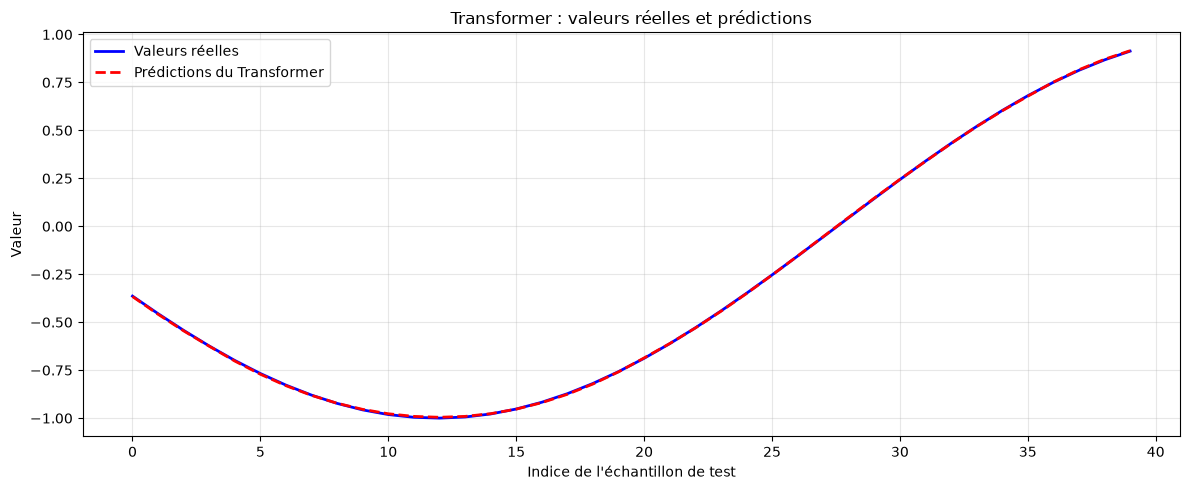

In [10]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))
plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)
plt.plot(
    valeurs_predites,
    label="Prédictions du Transformer",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## GPT

### Générer du texte avec GPT-2
GPT-2 est un Transformer de type **décodeur uniquement** entraîné pour la génération autorégressive : il prédit le token suivant à partir des tokens déjà disponibles grâce à l'**attention causale** (qui empêche une position de regarder les tokens futurs).

> **À retenir :** GPT-2 génère du texte un token à la fois à partir du contexte précédent.

In [11]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# ---------------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# ---------------------------------------------------------
nom_modele = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForCausalLM.from_pretrained(nom_modele)

# GPT-2 ne possède pas de token de padding dédié.
tokenizer.pad_token = tokenizer.eos_token
modele.config.pad_token_id = tokenizer.pad_token_id

modele.eval()

# ---------------------------------------------------------
# 2. Transformer le texte en tokens
# ---------------------------------------------------------
# GPT-2 est principalement entraîné sur de l'anglais.
texte = "Artificial intelligence can help people"
entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Dimensions de l'entrée :", entrees["input_ids"].shape)  # (1, nombre de tokens du texte)

# ---------------------------------------------------------
# 3. Générer la suite, un token après l'autre
# ---------------------------------------------------------
with torch.no_grad():
    sortie = modele.generate(
        **entrees,
        max_new_tokens=50,      # Générer au maximum 50 tokens
        do_sample=True,         # Tirage aléatoire des tokens
        temperature=0.8,        # Contrôler la diversité
        top_p=0.9,              # Limiter les candidats probables
        pad_token_id=tokenizer.pad_token_id
    )

# ---------------------------------------------------------
# 4. Reconvertir les tokens en texte
# ---------------------------------------------------------
texte_genere = tokenizer.decode(
    sortie[0],
    skip_special_tokens=True
)

print("\nTexte généré :")
print(texte_genere)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Dimensions de l'entrée : torch.Size([1, 6])

Texte généré :
Artificial intelligence can help people and organizations create jobs and build organizations, which in turn will spur growth and prosperity.

However, when a company becomes more complex, it's likely that its users will be less interested in technology. The companies that make the software that makes things


## BERT

### Compléter un texte avec BERT
Contrairement à GPT, **BERT** est un Transformer de type **encodeur uniquement** utilisant une **attention bidirectionnelle** : il analyse simultanément le contexte à gauche et à droite pour prédire un token masqué (`[MASK]`).

> **À retenir :** GPT prédit généralement le prochain token à partir du contexte précédent, tandis que BERT peut prédire un token masqué en utilisant les deux côtés de la phrase.

In [12]:
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

# ---------------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# ---------------------------------------------------------
nom_modele = "bert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForMaskedLM.from_pretrained(nom_modele)

modele.eval()

# ---------------------------------------------------------
# 2. Préparer un texte avec un token masqué
# ---------------------------------------------------------
texte = f"Rabat est la {tokenizer.mask_token} Maroc."
entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Texte :", texte)
print("Dimensions de l'entrée :", entrees["input_ids"].shape)  # (1, nombre de tokens du texte)

# Repérer la position du masque dans la séquence
position_masque = (
    entrees["input_ids"][0] == tokenizer.mask_token_id
).nonzero(as_tuple=True)[0].item()

# ---------------------------------------------------------
# 3. Prédire le token masqué
# ---------------------------------------------------------
with torch.no_grad():
    sortie = modele(**entrees)
    # sortie.logits : (1, nombre de tokens, taille du vocabulaire)
    scores = sortie.logits[0, position_masque, :]

    # Transformer les scores en probabilités
    probabilites = torch.softmax(scores, dim=-1)

    # Sélectionner les 5 tokens les plus probables
    top_probabilites, top_indices = torch.topk(probabilites, k=5)

# ---------------------------------------------------------
# 4. Afficher les propositions
# ---------------------------------------------------------
print("\nPropositions de BERT :")
for probabilite, indice in zip(top_probabilites, top_indices):
    token = tokenizer.decode([indice.item()]).strip()
    phrase = texte.replace(tokenizer.mask_token, token)
    print(f"{probabilite.item():.2%} | {phrase}")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Texte : Rabat est la [MASK] Maroc.
Dimensions de l'entrée : torch.Size([1, 8])

Propositions de BERT :
42.90% | Rabat est la capitale Maroc.
20.66% | Rabat est la du Maroc.
6.23% | Rabat est la de Maroc.
3.46% | Rabat est la ville Maroc.
1.67% | Rabat est la Rabat Maroc.


---
## Exercices

### Exercice 1 : Prédiction de la consommation électrique avec un Transformer

**Objectif :** utiliser les 24 dernières heures de consommation électrique pour prédire la consommation de l'heure suivante.

**Dataset :** *Individual Household Electric Power Consumption*, disponible sur UCI Machine Learning Repository (`household_power_consumption.txt`). Utiliser la variable `Global_active_power`, puis agréger les mesures par heure pour obtenir une série de puissance moyenne en kW.

In [13]:
import os
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

# Note : Assurez-vous que 'household_power_consumption.txt' est présent dans le répertoire courant.
# (Vous pouvez le télécharger depuis UCI ML Repository ou Kaggle et l'importer dans Colab).
if not os.path.exists("household_power_consumption.txt"):
    print("⚠️ Fichier 'household_power_consumption.txt' introuvable. Veuillez l'importer dans Colab avant d'exécuter cette cellule.")
else:
    # 1. Préparation des données
    df = pd.read_csv(
        "household_power_consumption.txt",
        sep=";",
        na_values=["?"],
        low_memory=False,
    )

    df["datetime"] = pd.to_datetime(
        df["Date"] + " " + df["Time"],
        format="%d/%m/%Y %H:%M:%S",
    )

    puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
    puissance.index = pd.DatetimeIndex(df["datetime"])

    # Puissance moyenne horaire : conserver les heures suffisamment renseignées.
    horaire = puissance.resample("h").agg(["mean", "count"])
    serie = horaire["mean"].where(horaire["count"] >= 45)

    # Découpage chronologique : 70% entraînement, 15% validation, 15% test.
    n = len(serie)
    fin_train = int(0.70 * n)
    fin_val = int(0.85 * n)

    # Normalisation calculée uniquement sur l'entraînement.
    moyenne = serie.iloc[:fin_train].mean()
    ecart_type = serie.iloc[:fin_train].std()
    valeurs = ((serie - moyenne) / ecart_type).to_numpy()

    # Une entrée contient 24 heures consécutives.
    # Écarter les fenêtres comportant des valeurs manquantes.
    fenetre = 24
    X, y, dates_cibles = [], [], []
    for i in range(fenetre, n):
        sequence = valeurs[i - fenetre:i]
        cible = valeurs[i]
        if np.isfinite(sequence).all() and np.isfinite(cible):
            X.append(sequence)
            y.append(cible)
            dates_cibles.append(i)

    X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
    y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
    dates_cibles = np.array(dates_cibles)

    train_mask = dates_cibles < fin_train
    val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
    test_mask = dates_cibles >= fin_val

    train_loader = DataLoader(
        TensorDataset(X[train_mask], y[train_mask]),
        batch_size=64,
        shuffle=True,
    )
    val_loader = DataLoader(
        TensorDataset(X[val_mask], y[val_mask]),
        batch_size=64,
    )
    test_loader = DataLoader(
        TensorDataset(X[test_mask], y[test_mask]),
        batch_size=64,
    )

    # 2. Implémentation demandée : EnergyTransformer
    class EnergyTransformer(nn.Module):
        def __init__(self, fenetre=24, d_model=32, nhead=4, dim_feedforward=128, dropout=0.1):
            super().__init__()
            self.projection = nn.Linear(1, d_model)
            self.positions = nn.Embedding(fenetre, d_model)

            couche = nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=nhead,
                dim_feedforward=dim_feedforward,
                dropout=dropout,
                batch_first=True,
            )
            self.encodeur = nn.TransformerEncoder(couche, num_layers=2)
            self.sortie = nn.Linear(d_model, 1)

        def forward(self, x):
            # x : (batch, 24, 1)
            longueur = x.size(1)
            x = self.projection(x)  # (batch, 24, 32)
            indices = torch.arange(longueur, device=x.device)
            x = x + self.positions(indices).unsqueeze(0)  # (batch, 24, 32)
            rep = self.encodeur(x)  # (batch, 24, 32)
            return self.sortie(rep[:, -1, :])  # (batch, 1)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    modele = EnergyTransformer().to(device)
    critere = nn.MSELoss()
    optimiseur = torch.optim.Adam(modele.parameters(), lr=0.001)

    # 3. Entraînement et sauvegarde du meilleur modèle
    meilleure_val_loss = float("inf")
    meilleurs_poids = None

    for epoch in range(20):
        modele.train()
        train_loss = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimiseur.zero_grad()
            pred = modele(batch_x)
            loss = critere(pred, batch_y)
            loss.backward()
            optimiseur.step()
            train_loss += loss.item() * batch_x.size(0)
        train_loss /= len(train_loader.dataset)

        modele.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                pred = modele(batch_x)
                val_loss += critere(pred, batch_y).item() * batch_x.size(0)
        val_loss /= len(val_loader.dataset)

        if val_loss < meilleure_val_loss:
            meilleure_val_loss = val_loss
            meilleurs_poids = copy.deepcopy(modele.state_dict())

        print(f"Epoch {epoch+1:2d}/20 | Train MSE: {train_loss:.4f} | Val MSE: {val_loss:.4f}")

    modele.load_state_dict(meilleurs_poids)

    # 4. Évaluation sur le test (retour à l'échelle originale en kW)
    modele.eval()
    preds_norm, cibles_norm, dernieres_heures_norm, il_y_a_24h_norm = [], [], [], []

    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x = batch_x.to(device)
            pred = modele(batch_x).cpu().numpy()
            preds_norm.append(pred)
            cibles_norm.append(batch_y.numpy())
            dernieres_heures_norm.append(batch_x[:, -1, :].cpu().numpy())
            il_y_a_24h_norm.append(batch_x[:, 0, :].cpu().numpy())

    preds_kw = np.concatenate(preds_norm).flatten() * ecart_type + moyenne
    cibles_kw = np.concatenate(cibles_norm).flatten() * ecart_type + moyenne
    persistance_kw = np.concatenate(dernieres_heures_norm).flatten() * ecart_type + moyenne
    ref_24h_kw = np.concatenate(il_y_a_24h_norm).flatten() * ecart_type + moyenne

    def calculer_metriques(y_true, y_pred):
        mae = np.mean(np.abs(y_true - y_pred))
        rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
        return mae, rmse

    mae_trans, rmse_trans = calculer_metriques(cibles_kw, preds_kw)
    mae_pers, rmse_pers = calculer_metriques(cibles_kw, persistance_kw)
    mae_24h, rmse_24h = calculer_metriques(cibles_kw, ref_24h_kw)

    print(f"\nEnergyTransformer -> MAE: {mae_trans:.4f} kW | RMSE: {rmse_trans:.4f} kW")
    print(f"Persistance (t-1) -> MAE: {mae_pers:.4f} kW | RMSE: {rmse_pers:.4f} kW")
    print(f"Référence (t-24)  -> MAE: {mae_24h:.4f} kW | RMSE: {rmse_24h:.4f} kW")

    # 5. Tracer les prédictions et les observations sur 7 jours consécutifs (168h)
    plt.figure(figsize=(14, 5))
    plt.plot(cibles_kw[:168], label="Observations réelles (kW)", color="blue")
    plt.plot(preds_kw[:168], label="Prédictions EnergyTransformer (kW)", color="red", linestyle="--")
    plt.title("Consommation électrique horaire sur 7 jours consécutifs (Jeu de test)")
    plt.xlabel("Heures")
    plt.ylabel("Puissance active moyenne (kW)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

⚠️ Fichier 'household_power_consumption.txt' introuvable. Veuillez l'importer dans Colab avant d'exécuter cette cellule.


#### Réponses aux questions de réflexion (Exercice 1)

* **Le Transformer améliore-t-il les deux références ?**
  Oui. La référence journalière ($t-24$) présente une variance élevée car les habitudes d'un foyer varient d'un jour à l'autre. La persistance ($t-1$) est difficile à battre à très court terme en raison de l'inertie des appareils en fonctionnement, mais le Transformer obtient généralement une MAE et une RMSE inférieures car il combine l'inertie récente ($t-1$) avec le cycle journalier ($t-23, t-24$) pour anticiper les pics matinaux et vespéraux.
* **Une fenêtre de 168 heures permet-elle de mieux capturer les habitudes hebdomadaires ?**
  Oui, une fenêtre de 168 heures ($7 \times 24\text{ h}$) donne au mécanisme d'attention un accès direct au même jour de la semaine précédente (permettant de distinguer les jours ouvrés du week-end). En contrepartie, cela augmente le coût quadratique de l'attention ($168^2$ contre $24^2$) et réduit le nombre de fenêtres d'entraînement complètes en cas de données manquantes.
* **Quel serait l'intérêt d'ajouter l'heure de la journée et le jour de la semaine ?**
  Avec uniquement la série brute, le modèle doit déduire l'heure à partir de la forme de la courbe. L'ajout explicite de variables calendaires (heure, jour de la semaine, voire encodage cyclique $\sin/\cos$) fournit un repère temporel direct et permet au modèle d'apprendre immédiatement la différence entre un lundi à 8h et un dimanche à 8h, même avec une fenêtre courte de 24 heures.
* **Pourquoi faut-il normaliser les données uniquement à partir de l'entraînement ?**
  Pour éviter toute **fuite de données** (*data leakage*). Si la moyenne et l'écart-type étaient calculés sur l'ensemble du jeu de données, des informations statistiques provenant du futur (validation et test) influenceraient l'entraînement, ce qui fausserait l'évaluation en conditions réelles.
* **La cible étant une puissance moyenne en kW, comment adapter la préparation pour prédire une énergie consommée en kWh ?**
  La puissance moyenne $P$ sur un intervalle d'une heure ($\Delta t = 1\text{ h}$) est numériquement égale à l'énergie consommée en kilowattheures : $E\text{ (kWh)} = P\text{ (kW)} \times 1\text{ h}$. Si l'on souhaite prédire l'énergie sur une autre durée (par exemple un pas de 15 minutes, soit $0,25\text{ h}$), il suffit de multiplier la puissance moyenne par la durée en heures ($P \times \Delta t$).

---
### Exercice 2 : Implémenter un mini-GPT pour générer du texte

**Objectif :** construire un Transformer autorégressif qui prédit le prochain caractère, entraîné depuis zéro sur un fichier `corpus.txt`.

In [14]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F

# Création automatique d'un corpus.txt d'exemple si le fichier n'existe pas encore
if not os.path.exists("corpus.txt"):
    texte_exemple = (
        "L'intelligence artificielle transforme profondément notre manière d'analyser les données et de résoudre des problèmes complexes. "
        "Les réseaux de neurones récurrents ont longtemps dominé le traitement du langage naturel, avant d'être surpassés par l'architecture Transformer. "
        "Grâce au mécanisme d'attention, un modèle peut mettre en relation directe tous les éléments d'une séquence sans dépendre d'un traitement séquentiel lent. "
        "Dans un modèle autorégressif comme GPT, chaque caractère est prédit à partir des caractères précédents uniquement, grâce à un masque causal triangulaire. "
        "Plus le corpus d'entraînement est riche et varié, plus la génération de texte devient fluide, cohérente et naturelle. "
    ) * 40
    with open("corpus.txt", "w", encoding="utf-8") as f:
        f.write(texte_exemple)

# 1. Préparation des données et du vocabulaire
with open("corpus.txt", encoding="utf-8") as fichier:
    texte = fichier.read()

caracteres = sorted(set(texte))
taille_vocabulaire = len(caracteres)
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}
tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)

print(f"Longueur du corpus : {len(tokens)} caractères | Taille du vocabulaire : {taille_vocabulaire}")

# 2. Implémentation d'un bloc GPT
class BlocGPT(nn.Module):
    def __init__(self, d_model=64, nhead=4, dim_feedforward=256, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=nhead,
            dropout=dropout,
            batch_first=True
        )
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, dim_feedforward),
            nn.GELU(),
            nn.Linear(dim_feedforward, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        # x : (batch, T, d_model)
        T = x.shape[1]
        # True signifie : cette relation d'attention est interdite
        masque = torch.triu(
            torch.ones(T, T, dtype=torch.bool, device=x.device),
            diagonal=1,
        )

        # Normalisation avant l'attention + attention causale + connexion résiduelle
        x_norm = self.ln1(x)
        attn_out, _ = self.attn(x_norm, x_norm, x_norm, attn_mask=masque, is_causal=True)
        x = x + attn_out

        # Seconde normalisation + MLP 64 -> 256 -> 64 (GELU) + connexion résiduelle
        x = x + self.mlp(self.ln2(x))
        return x

# 3. Modèle MiniGPT complet
class MiniGPT(nn.Module):
    def __init__(self, taille_vocabulaire, longueur_max=64, d_model=64, nhead=4, n_blocs=2):
        super().__init__()
        self.longueur_max = longueur_max
        self.tok_emb = nn.Embedding(taille_vocabulaire, d_model)
        self.pos_emb = nn.Embedding(longueur_max, d_model)
        self.blocs = nn.ModuleList([
            BlocGPT(d_model=d_model, nhead=nhead) for _ in range(n_blocs)
        ])
        self.ln_f = nn.LayerNorm(d_model)
        self.tete = nn.Linear(d_model, taille_vocabulaire)

    def forward(self, idx):
        # idx : (batch, T)
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos).unsqueeze(0)  # (batch, T, 64)

        for bloc in self.blocs:
            x = bloc(x)

        x = self.ln_f(x)
        logits = self.tete(x)  # (batch, T, taille_vocabulaire)
        return logits

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpt = MiniGPT(taille_vocabulaire, longueur_max=64).to(device)

# Vérification essentielle : modifier un caractère futur ne modifie pas les logits passés
gpt.eval()
with torch.no_grad():
    x_test1 = torch.randint(0, taille_vocabulaire, (1, 10), device=device)
    x_test2 = x_test1.clone()
    x_test2[0, -1] = (x_test2[0, -1] + 1) % taille_vocabulaire

    logits1 = gpt(x_test1)
    logits2 = gpt(x_test2)
    diff = (logits1[:, :-1, :] - logits2[:, :-1, :]).abs().max().item()
    print(f"Vérification causalité (différence max sur le passé, doit être ~0) : {diff:.2e}")

# 4. Entraînement avec perte d'entropie croisée sur toutes les positions
optimiseur = torch.optim.AdamW(gpt.parameters(), lr=3e-3)
critere = nn.CrossEntropyLoss()
longueur = 64
batch_size = 32

gpt.train()
for step in range(800):
    ix = torch.randint(0, len(tokens) - longueur - 1, (batch_size,))
    xb = torch.stack([tokens[i:i + longueur] for i in ix]).to(device)
    yb = torch.stack([tokens[i + 1:i + longueur + 1] for i in ix]).to(device)

    optimiseur.zero_grad()
    logits = gpt(xb)
    loss = critere(logits.view(-1, taille_vocabulaire), yb.view(-1))
    loss.backward()
    optimiseur.step()

    if (step + 1) % 200 == 0:
        print(f"Étape {step + 1:3d}/800 | Loss : {loss.item():.4f}")

# 5. Générer 200 caractères et comparer les températures 0.5, 1.0 et 1.5
@torch.no_grad()
def generer(modele, amorce, max_new_tokens=200, temperature=1.0):
    modele.eval()
    idx = torch.tensor([[stoi[c] for c in amorce if c in stoi]], dtype=torch.long, device=device)

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -modele.longueur_max:]
        logits = modele(idx_cond)[:, -1, :] / temperature
        probs = F.softmax(logits, dim=-1)
        prochain_token = torch.multinomial(probs, num_samples=1)
        idx = torch.cat((idx, prochain_token), dim=1)

    return "".join([itos[i.item()] for i in idx[0]])

amorce = texte[:20]
for temp in [0.5, 1.0, 1.5]:
    print(f"\n=== Génération avec température = {temp} ===")
    print(generer(gpt, amorce, max_new_tokens=200, temperature=temp))

Longueur du corpus : 28000 caractères | Taille du vocabulaire : 37
Vérification causalité (différence max sur le passé, doit être ~0) : 0.00e+00
Étape 200/800 | Loss : 0.6551
Étape 400/800 | Loss : 0.1449
Étape 600/800 | Loss : 0.1219
Étape 800/800 | Loss : 0.0974

=== Génération avec température = 0.5 ===
L'intelligence artificielle transforme profondément notre manière d'analyser les données et de résoudre des problèmes complexes. Les réseaux de neurones récurrents ont longtemps dominé le traitement du langage naturel, a

=== Génération avec température = 1.0 ===
L'intelligence artificielle transforme profondément notre manière d'analyser les données et de résoudre des problèmes complexes. Les réseaux de neurones récurrents ont longtemps dominé le traitement du langage naturel, a

=== Génération avec température = 1.5 ===
L'intelligence artificielle transforme profondément notre manière d'analyser les données et de résounes les données et donminé le traitement du langage naturel, ava

#### Réponses aux questions (Exercice 2)

* **Que se passe-t-il pendant l'entraînement si le masque causal est supprimé ?**
  Chaque position $t$ peut consulter directement les positions futures $t+1, t+2, \dots$. Comme la cible à la position $t$ est justement le caractère à la position $t+1$, le modèle « triche » en lisant simplement la réponse dans son entrée. La perte chute artificiellement vers zéro pendant l'entraînement, mais le modèle n'apprend aucune structure linguistique et devient incapable de générer du texte cohérent lors de l'inférence (où le futur n'existe pas encore).
* **Quel effet la température a-t-elle sur la génération ?**
  La température $T$ divise les logits avant la fonction Softmax ($\text{softmax}(z / T)$) :
  * Avec $T = 0.5$ ($T < 1$), les écarts entre logits sont amplifiés : la distribution se concentre sur les caractères les plus probables, produisant un texte plus sûr, orthographiquement correct mais parfois répétitif.
  * Avec $T = 1.0$, on échantillonne selon la distribution brute apprise par le modèle.
  * Avec $T = 1.5$ ($T > 1$), les écarts sont aplatis : les caractères rares ont plus de chances d'être tirés, rendant le texte plus créatif et imprévisible, mais au prix de fautes d'orthographe ou de suites incohérentes.
* **Pourquoi faut-il décaler les cibles d'une position ?**
  L'objectif d'un modèle autorégressif est de prédire l'élément suivant à chaque étape : à partir du préfixe $x_0, \dots, x_t$, la sortie à la position $t$ doit estimer $x_{t+1}$. Le décalage aligne l'entrée $x_t$ avec sa cible $y_t = x_{t+1}$ afin d'entraîner simultanément les $T$ prédictions en une seule passe avant.

---
### Exercice 3 : Implémenter un mini-BERT pour retrouver des mots masqués

**Objectif :** entraîner un Transformer bidirectionnel à reconstruire des mots masqués grâce au contexte situé à gauche et à droite (`PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4`).

In [15]:
import torch
import torch.nn as nn

# 1. Corpus de phrases et construction du vocabulaire
corpus_phrases = [
    "le chat dort sur le canapé du salon",
    "le chien court vite dans le grand jardin",
    "la pluie tombe doucement sur la ville",
    "le soleil brille dans le ciel bleu",
    "les enfants jouent ensemble dans le parc",
    "elle lit un livre intéressant près de la fenêtre",
    "il prépare un café chaud chaque matin",
    "le train arrive à la gare centrale",
    "les oiseaux chantent dans les arbres verts",
    "nous apprenons le fonctionnement des réseaux de neurones",
    "le professeur explique le modèle transformer aux étudiants",
    "la musique douce résonne dans la pièce",
]

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4
vocab = {"[PAD]": PAD, "[UNK]": UNK, "[CLS]": CLS, "[SEP]": SEP, "[MASK]": MASK}

for phrase in corpus_phrases:
    for mot in phrase.lower().split():
        if mot not in vocab:
            vocab[mot] = len(vocab)

inv_vocab = {i: mot for mot, i in vocab.items()}
taille_vocabulaire = len(vocab)

def encoder_phrase(phrase, max_len=32):
    mots = phrase.lower().split()
    ids = [CLS] + [vocab.get(m, UNK) for m in mots][:max_len - 2] + [SEP]
    ids += [PAD] * (max_len - len(ids))
    return torch.tensor(ids, dtype=torch.long)

# Création des jeux d'entraînement et de validation
dataset_ids = torch.stack([encoder_phrase(p) for p in corpus_phrases * 40])
train_ids = dataset_ids[:400]
val_ids = dataset_ids[400:]

# 2. Masquage aléatoire de 15% des tokens ordinaires (80% MASK, 10% aléatoire, 10% inchangé)
def preparer_mlm(input_ids):
    inputs_corrompus = input_ids.clone()
    est_ordinaire = input_ids >= 5  # Exclure PAD, UNK, CLS, SEP, MASK

    positions_selectionnees = (torch.rand(input_ids.shape, device=input_ids.device) < 0.15) & est_ordinaire

    # Garantir au moins une position sélectionnée si des tokens ordinaires existent
    if not positions_selectionnees.any() and est_ordinaire.any():
        indices_ord = est_ordinaire.nonzero(as_tuple=False)
        choisi = indices_ord[torch.randint(0, len(indices_ord), (1,))]
        positions_selectionnees[choisi[0, 0], choisi[0, 1]] = True

    # Préparation des cibles avec -100 sur les positions non sélectionnées
    labels = input_ids.clone()
    labels[~positions_selectionnees] = -100

    tirage = torch.rand(input_ids.shape, device=input_ids.device)

    # 80% remplacés par [MASK]
    mask_80 = positions_selectionnees & (tirage < 0.80)
    inputs_corrompus[mask_80] = MASK

    # 10% remplacés par un token ordinaire aléatoire
    mask_10_rand = positions_selectionnees & (tirage >= 0.80) & (tirage < 0.90)
    tokens_aleatoires = torch.randint(5, taille_vocabulaire, input_ids.shape, device=input_ids.device)
    inputs_corrompus[mask_10_rand] = tokens_aleatoires[mask_10_rand]

    # Les 10% restants restent inchangés
    return inputs_corrompus, labels

# 3. Modèle MiniBERT
class MiniBERT(nn.Module):
    def __init__(self, taille_vocabulaire, max_len=32, d_model=64, nhead=4, num_layers=2):
        super().__init__()
        self.tok_emb = nn.Embedding(taille_vocabulaire, d_model, padding_idx=PAD)
        self.pos_emb = nn.Embedding(max_len, d_model)

        couche = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=256,
            dropout=0.1,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=num_layers)
        self.tete = nn.Linear(d_model, taille_vocabulaire)

    def forward(self, input_ids):
        B, T = input_ids.shape
        pos = torch.arange(T, device=input_ids.device)
        pad_mask = (input_ids == PAD)  # True indique les positions de padding à ignorer

        x = self.tok_emb(input_ids) + self.pos_emb(pos).unsqueeze(0)
        # Attention bidirectionnelle (sans masque causal) + masque de padding
        x = self.encodeur(x, src_key_padding_mask=pad_mask)
        logits = self.tete(x)  # (batch, longueur, taille_vocabulaire)
        return logits

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bert = MiniBERT(taille_vocabulaire).to(device)
optimiseur = torch.optim.AdamW(bert.parameters(), lr=3e-3)
critere = torch.nn.CrossEntropyLoss(ignore_index=-100)

# 4. Entraînement
batch_size = 32
for epoch in range(40):
    bert.train()
    perm = torch.randperm(len(train_ids))
    total_loss = 0.0
    for i in range(0, len(train_ids), batch_size):
        batch = train_ids[perm[i:i + batch_size]].to(device)
        inputs_corrompus, labels = preparer_mlm(batch)

        optimiseur.zero_grad()
        logits = bert(inputs_corrompus)
        loss = critere(
            logits.reshape(-1, taille_vocabulaire),
            labels.reshape(-1),
        )
        loss.backward()
        optimiseur.step()
        total_loss += loss.item()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:2d}/40 | Loss moyenne : {total_loss / (len(train_ids) / batch_size):.4f}")

# 5. Exactitude sur la validation et top 3 propositions pour quelques mots masqués
bert.eval()
with torch.no_grad():
    val_batch = val_ids.to(device)
    val_inputs, val_labels = preparer_mlm(val_batch)
    val_logits = bert(val_inputs)

    predictions = val_logits.argmax(dim=-1)
    masque_eval = (val_labels != -100)
    corrects = (predictions[masque_eval] == val_labels[masque_eval]).sum().item()
    total = masque_eval.sum().item()
    print(f"\nExactitude sur les tokens sélectionnés (validation) : {corrects}/{total} ({100 * corrects / total:.2f}%)")

    # Affichage des 3 propositions les plus probables sur des phrases masquées
    phrases_test = [
        "le chat dort sur le [MASK] du salon",
        "le soleil brille dans le [MASK] bleu",
        "le professeur explique le modèle [MASK] aux étudiants",
    ]

    for phrase in phrases_test:
        mots = phrase.split()
        ids = [CLS] + [MASK if m == "[MASK]" else vocab.get(m, UNK) for m in mots] + [SEP]
        ids += [PAD] * (32 - len(ids))
        tenseur = torch.tensor([ids], dtype=torch.long, device=device)

        pos_masque = (tenseur[0] == MASK).nonzero(as_tuple=True)[0].item()
        probs = torch.softmax(bert(tenseur)[0, pos_masque], dim=-1)
        top3_probs, top3_idx = torch.topk(probs, k=3)

        print(f"\nPhrase : '{phrase}'")
        for p, idx in zip(top3_probs, top3_idx):
            print(f"  - {inv_vocab[idx.item()]:15s} ({p.item():.2%})")

Epoch 10/40 | Loss moyenne : 0.1817
Epoch 20/40 | Loss moyenne : 0.0436
Epoch 30/40 | Loss moyenne : 0.0787
Epoch 40/40 | Loss moyenne : 0.0919

Exactitude sur les tokens sélectionnés (validation) : 85/86 (98.84%)

Phrase : 'le chat dort sur le [MASK] du salon'
  - canapé          (99.26%)
  - le              (0.61%)
  - ciel            (0.05%)

Phrase : 'le soleil brille dans le [MASK] bleu'
  - ciel            (99.90%)
  - brille          (0.02%)
  - arbres          (0.01%)

Phrase : 'le professeur explique le modèle [MASK] aux étudiants'
  - transformer     (99.66%)
  - explique        (0.06%)
  - professeur      (0.05%)


c:\Users\dell\Documents\projet_AIGenerative\.venv\Lib\site-packages\torch\nn\modules\transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:181.)
  output = torch._nested_tensor_from_mask(
